# EDA for Red Blend (Genereic), 	Syrah, Italian Reds, 	Zinfandel, Iberian Whites, and Light & Central European Reds wines

# Importing the data

In [1]:
import pandas as pd

wines = pd.read_csv("winemag-data-130k-v2.csv")
wines.head()

,Unnamed: 0,country,description,designation,points,price,province,region_1,region_2,taster_name,taster_twitter_handle,title,variety,winery
0,0,Italy,"Aromas include tropical fruit, broom, brimston...",Vulkà Bianco,87,NaN,Sicily & Sardinia,Etna,NaN,Kerin O’Keefe,@kerinokeefe,Nicosia 2013 Vulkà Bianco (Etna),White Blend,Nicosia
1,1,Portugal,"This is ripe and fruity, a wine that is smooth...",Avidagos,87,15.0,Douro,NaN,NaN,Roger Voss,@vossroger,Quinta dos Avidagos 2011 Avidagos Red (Douro),Portuguese Red,Quinta dos Avidagos
2,2,US,"Tart and snappy, the flavors of lime flesh and...",NaN,87,14.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Rainstorm 2013 Pinot Gris (Willamette Valley),Pinot Gris,Rainstorm
3,3,US,"Pineapple rind, lemon pith and orange blossom ...",Reserve Late Harvest,87,13.0,Michigan,Lake Michigan Shore,NaN,Alexander Peartree,NaN,St. Julian 2013 Reserve Late Harvest Riesling ...,Riesling,St. Julian
4,4,US,"Much like the regular bottling from 2012, this...",Vintner's Reserve Wild Child Block,87,65.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Sweet Cheeks 2012 Vintner's Reserve Wild Child...,Pinot Noir,Sweet Cheeks


In [ ]:
wines.shape

(129971, 14)

In [2]:
wines.isna().sum()

,0
Unnamed: 0,0
country,63
description,0
designation,37465
points,0
price,8996
province,63
region_1,21247
region_2,79460
taster_name,26244


# Regrouping by wine style types

In [4]:
# creating the mapping for style_groups

# 1. Load your style groups mapping file
groups_df = pd.read_csv("wine_style_groups_final.csv")

# 2. Build a mapping dictionary from variety name -> style_group
variety_to_style = {}

for _, row in groups_df.iterrows():
    style = row["style_group"]
    # Split the semicolon-separated varieties string and strip whitespace
    varieties = [v.strip() for v in str(row["varieties"]).split(";")]
    for var in varieties:
        variety_to_style[var] = style

# 3. Apply this mapping to your main wine dataset (assuming your DataFrame is named `df`)
# This creates the new 'style_group' column based on the 'variety' column

wines['variety'] = wines['variety'].str.strip()  # Remove leading/trailing spaces
wines["style_group"] = wines["variety"].map(variety_to_style)

# 4. Check if any varieties were missed (unmapped)
unmapped = wines[wines["style_group"].isna()]["variety"].unique()
if len(unmapped) > 0:
    print(
        f"Warning: {len(unmapped)} unique varieties were not found in the mapping:"
    )
    print(unmapped[:10])  # Print a few examples if any exist
else:
    print("Success! All wine varieties successfully mapped to style groups.")

# Preview your new column
print(wines[["variety", "style_group"]].head(10))

[nan]
              variety               style_group
0         White Blend     White Blend (generic)
1      Portuguese Red              Iberian Reds
2          Pinot Gris  Pinot Gris & Pinot Blanc
3            Riesling                  Riesling
4          Pinot Noir                Pinot Noir
5  Tempranillo-Merlot       Red Blend (generic)
6            Frappato              Italian Reds
7      Gewürztraminer           Aromatic Whites
8      Gewürztraminer           Aromatic Whites
9          Pinot Gris  Pinot Gris & Pinot Blanc


In [ ]:
# checking we get 32 unique style groups
len(wines['style_group'].unique())

32

# Filtering the dataset

In [5]:
wine_filtered = wines[wines['style_group'].isin(['Red Blend (generic)', 'Syrah', 'Italian Reds', 'Zinfandel', 'Iberian Whites', 'Light & Central European Reds'])]
wine_filtered.head()

,Unnamed: 0,country,description,designation,points,price,province,region_1,region_2,taster_name,taster_twitter_handle,title,variety,winery,style_group
5,5,Spain,Blackberry and raspberry aromas show a typical...,Ars In Vitro,87,15.0,Northern Spain,Navarra,NaN,Michael Schachner,@wineschach,Tandem 2011 Ars In Vitro Tempranillo-Merlot (N...,Tempranillo-Merlot,Tandem,Red Blend (generic)
6,6,Italy,"Here's a bright, informal red that opens with ...",Belsito,87,16.0,Sicily & Sardinia,Vittoria,NaN,Kerin O’Keefe,@kerinokeefe,Terre di Giurfo 2013 Belsito Frappato (Vittoria),Frappato,Terre di Giurfo,Italian Reds
13,13,Italy,This is dominated by oak and oak-driven aromas...,Rosso,87,NaN,Sicily & Sardinia,Etna,NaN,Kerin O’Keefe,@kerinokeefe,Masseria Setteporte 2012 Rosso (Etna),Nerello Mascalese,Masseria Setteporte,Italian Reds
20,20,US,Ripe aromas of dark berries mingle with ample ...,Vin de Maison,87,23.0,Virginia,Virginia,NaN,Alexander Peartree,NaN,Quiévremont 2012 Vin de Maison Red (Virginia),Red Blend,Quiévremont,Red Blend (generic)
24,24,Italy,"Aromas of prune, blackcurrant, toast and oak c...",Aynat,87,35.0,Sicily & Sardinia,Sicilia,NaN,Kerin O’Keefe,@kerinokeefe,Canicattì 2009 Aynat Nero d'Avola (Sicilia),Nero d'Avola,Canicattì,Italian Reds


In [6]:
# checking there are only 6 remaining style groups

print(f"Wine styles: {wine_filtered['style_group'].unique()} \n Number of Wine styles: {len(wine_filtered['style_group'].unique())}")

Wine styles: ['Red Blend (generic)' 'Italian Reds' 'Light & Central European Reds'
 'Zinfandel' 'Iberian Whites' 'Syrah'] 
 Number of Wine styles: 6


In [ ]:
wine_filtered.shape

(25491, 15)

In [96]:
# Get the number of reviews per style group
review_counts = wine_filtered['style_group'].value_counts()

print(review_counts)

style_group
Red Blend (generic)              9683
Syrah                            4978
Italian Reds                     3438
Zinfandel                        2936
Iberian Whites                   2669
Light & Central European Reds    1787
Name: count, dtype: int64


# Creating the TF-IDF

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS

# 1. Define your custom wine-specific filler words to ignore
wine_filler_words = [
    'wine', 'wines',
    'flavor', 'flavors',
    'aroma', 'aromas',
    'notes',
    'palate',
    'finish',
    'drink',
    'tasting',
    'bottles',
    'bottle',
    'blend',
    'syrah',
    'offers',
    'opens',
    'zinfandel',
    'zin',
    'bodied',
    'alcohol',
    'structure',
    'lead','nose',
    'like'
]

# 2. Combine standard English stop words with your custom list
custom_stop_words = list(ENGLISH_STOP_WORDS.union(wine_filler_words))

# 3. Re-initialize your vectorizer with the expanded stop-word list
vectorizer = TfidfVectorizer(
    stop_words=custom_stop_words,
    max_features=5000,
    ngram_range=(1, 2)
)

# 4. Re-run your TF-IDF transformation
X_tfidf = vectorizer.fit_transform(wine_filtered['description'])

In [59]:
feature_names = vectorizer.get_feature_names_out()

# Top Words for each Style group

In [60]:
import pandas as pd
import numpy as np

# 1. Get feature names from your vectorizer
feature_names = vectorizer.get_feature_names_out()

# 2. Get the list of style groups from your dataframe
style_groups = wine_filtered['style_group'].unique()

# List to hold dictionaries for our final DataFrame
summary_data = []

# Define how many top features you want per category
top_n = 10

# 3. Loop through each style group
for style in style_groups:
    # Create the boolean mask for the current style group
    mask = (wine_filtered['style_group'] == style).values

    # Sum the TF-IDF scores for this specific style group
    style_tfidf_sum = np.array(X_tfidf[mask].sum(axis=0)).flatten()

    # Create a temp dataframe for all words/phrases and their scores
    df_temp = pd.DataFrame({
        'feature': feature_names,
        'score': style_tfidf_sum
    })

    # Separate into Unigrams (Words - no space) and Bigrams (Phrases - contains space)
    df_words = df_temp[~df_temp['feature'].str.contains(' ')].sort_values(by='score', ascending=False)
    df_bigrams = df_temp[df_temp['feature'].str.contains(' ')].sort_values(by='score', ascending=False)

    # Append top N words to our list
    for rank, (idx, row) in enumerate(df_words.head(top_n).iterrows(), 1):
        summary_data.append({
            'style_group': style,
            'feature_type': 'Word',
            'rank': rank,
            'feature': row['feature'],
            'score': round(row['score'], 4)
        })

    # Append top N bigrams to our list
    for rank, (idx, row) in enumerate(df_bigrams.head(top_n).iterrows(), 1):
        summary_data.append({
            'style_group': style,
            'feature_type': 'Bigram',
            'rank': rank,
            'feature': row['feature'],
            'score': round(row['score'], 4)
        })

# 4. Convert the final list into a clean Pandas DataFrame
df_final_summary = pd.DataFrame(summary_data)

# Investigating top 10 words for each wine style

# Red Blend (generic)

We are investigating what words correspond or describe the Red blends.

In [61]:
pd.set_option('display.max_colwidth', None)

In [62]:
df_final_summary[df_final_summary['style_group'] == "Red Blend (generic)"]

,style_group,feature_type,rank,feature,score
0,Red Blend (generic),Word,1,cabernet,368.7216
1,Red Blend (generic),Word,2,black,345.2551
2,Red Blend (generic),Word,3,cherry,320.9988
3,Red Blend (generic),Word,4,tannins,297.8511
4,Red Blend (generic),Word,5,red,279.2703
5,Red Blend (generic),Word,6,sauvignon,278.5565
6,Red Blend (generic),Word,7,fruit,259.0152
7,Red Blend (generic),Word,8,merlot,251.1347
8,Red Blend (generic),Word,9,berry,246.6478
9,Red Blend (generic),Word,10,plum,234.9389


In [63]:
red_blend = wine_filtered[wine_filtered['style_group'] == "Red Blend (generic)"]

In [64]:
import re

# 1. Get your top 10 words/phrases as a list
# (Assuming df_vocab is your sorted vocabulary dataframe from earlier)
top_words = df_final_summary[df_final_summary['style_group'] == "Red Blend (generic)"]['feature'].tolist()

print("Top 10 words being filtered out:", top_words)

# 2. Escape any special regex characters and join them with '|' (which means OR)
escaped_words = [re.escape(word) for word in top_words]
pattern = '|'.join(escaped_words)

# 3. Filter the dataframe
# The '~' means "NOT", so this keeps rows that DO NOT contain any of the pattern words
no_top_words_df = red_blend[~red_blend['description'].str.contains(pattern, case=False, regex=True)]

print(f"Original dataset size: {len(red_blend)}")
print(f"Rows remaining without top 10 words: {len(no_top_words_df)}")

Top 10 words being filtered out: ['cabernet', 'black', 'cherry', 'tannins', 'red', 'sauvignon', 'fruit', 'merlot', 'berry', 'plum', 'cabernet sauvignon', 'black cherry', 'cabernet franc', 'petit verdot', 'black fruit', 'petite sirah', 'merlot cabernet', 'sauvignon merlot', 'black pepper', 'white pepper']
Original dataset size: 9683
Rows remaining without top 10 words: 182


The top 10 words and top 10 bigrams don't capture 182 (1.88%) of reviews of the Red Blends. The reviews not captured can be seen below.

In [65]:
no_top_words_df[['style_group','description']].head(10)

,style_group,description
813,Red Blend (generic),"Built for early consumption, this blend of 59% Grenache, 22% Shiraz and 19% Mataro is lush and warm, offering chocolaty notes alongside hints of brown sugar, grilled meat and blueberries. Drink now–2022."
974,Red Blend (generic),"It's soft, slightly oxidized, and generic. It's pleasantly quaffable, marked in the finish by some rather bitter toast."
992,Red Blend (generic),"Made from Fer Servadou, Duras and Syrah, this is a wine with a truly local pedigree and a modern style, with prominent new wood. There are aromas that talk of wild heather and a dry landscape and palate notes of spice, ripe berries and prunes."
1478,Red Blend (generic),"This 60-40 blend features gentle aromas of vanilla and cassis in a medium-bodied, creamy-smooth format. It's not powerful or complex, but offers pure cassis and vanilla flavors tinged with chocolate on the finish. Good value."
2008,Red Blend (generic),"This is soft and easy in texture, light in flavors and slightly sweet. Light to medium bodied, it has very little tannin or astringency, is low in acidity and quiet on the finish."
2282,Red Blend (generic),"This shows delicate floral aromas along with dominant bell pepper and sawdust sensations. The palate is dominated by oaky flavors of roasted coffee beans and espresso, giving the wine an anonymous personality and style."
2287,Red Blend (generic),"From a very hot and difficult vintage, this Chianti Classico has unusual aromas of dill, thyme and toasted oak that carry over to the palate. It's already evolved with a short finish."
3299,Red Blend (generic),"If all you're after is size, then sign on the dotted line. This blend is a monster that weighs in at 15.5%, so be ready for intensely sweet flavors of grape essence and licorice. To this judge, the wine has a lot of gumption but isn't what I'd want to drink glass after glass, day after day. It's lumbering, heavy but oh so sweet and dessert-like."
3790,Red Blend (generic),"This was fermented from dried Barbera, Sangiovese and Nebbiolo grapes, concentrating the flavors yet retaining an elegant lightness that belies its high alcohol. Mixed fig, raisin, soy and chocolate components lend extra complexity. It's drinking well and is perfect for near-term consumption."
5173,Red Blend (generic),"Anywhere but in Oregon, this could be labeled Pinot Noir, which makes up 80% of the blend; the rest is Zinfandel. It's a combination that makes sense in the Columbia Gorge. The Pinot is more earthy and tannic than in the Willamette Valley, and the Zin lighter than you find in California. The result is a wine tasting of wild cherries, tart, spicy and quite quaffable."


# Syrah

We are investigating what words correspond or describe the Syrah.

In [67]:
df_final_summary[df_final_summary['style_group'] == "Syrah"]

,style_group,feature_type,rank,feature,score
100,Syrah,Word,1,fruit,195.2789
101,Syrah,Word,2,black,163.2706
102,Syrah,Word,3,pepper,136.1003
103,Syrah,Word,4,blackberry,116.8896
104,Syrah,Word,5,tannins,109.3157
105,Syrah,Word,6,dark,99.2101
106,Syrah,Word,7,cherry,92.2175
107,Syrah,Word,8,oak,88.8013
108,Syrah,Word,9,chocolate,82.3338
109,Syrah,Word,10,meat,82.1721


The words seem similar to the Red Blends but also have 'chocolate' as a descriptor and 'black olive'

In [68]:
syrah = wine_filtered[wine_filtered['style_group'] == "Syrah"]

In [69]:
import re

# 1. Get your top 10 words/phrases as a list
# (Assuming df_vocab is your sorted vocabulary dataframe from earlier)
top_words = df_final_summary[df_final_summary['style_group'] == "Syrah"]['feature'].tolist()

print("Top 10 words being filtered out:", top_words)

# 2. Escape any special regex characters and join them with '|' (which means OR)
escaped_words = [re.escape(word) for word in top_words]
pattern = '|'.join(escaped_words)

# 3. Filter the dataframe
# The '~' means "NOT", so this keeps rows that DO NOT contain any of the pattern words
no_top_words_df = syrah[~syrah['description'].str.contains(pattern, case=False, regex=True)]

print(f"Original dataset size: {len(syrah)}")
print(f"Rows remaining without top 10 words: {len(no_top_words_df)}")

Top 10 words being filtered out: ['fruit', 'black', 'pepper', 'blackberry', 'tannins', 'dark', 'cherry', 'oak', 'chocolate', 'meat', 'black pepper', 'black cherry', 'smoked meat', 'black fruit', 'dark fruit', 'black olive', 'white pepper', 'dark chocolate', 'blue fruit', 'cherry fruit']
Original dataset size: 4978
Rows remaining without top 10 words: 269


The top 10 words and bigrams don't capture 269 (5.4%) of the reviews for Syrah's. Reviews not captured are shown below.

In [70]:
no_top_words_df[['style_group','description']].head(10)

,style_group,description
1769,Syrah,"Flat boysenberry and plum aromas are jammy and a bit floral. This feels clipped and rugged, with reedy plum and raspberry flavors that finish short."
2541,Syrah,"This is a medium-bodied, spicy rendering of Syrah. Cherries, herbs and spice all mingle easily, while the silky texture is its calling card. Drink now–2023."
2579,Syrah,"Coming from one of the state's premier Syrah vineyards, this warm-vintage wine seems aromatically quiet, with light aromas of funk, earth, red berries and coffee. Flavors are generous and ripe, with the alcohol occasionally poking out."
2608,Syrah,"Though labeled simply Columbia Valley, this is a classic example of Wahluke Slope Syrah. Well-integrated layers of citrus, berry, roasted coffee beans, vanilla cookie and Graham cracker combine into a most accessible, yet complex wine. It's ready to drink, and should be consumed over the next 3–4 years."
3070,Syrah,"A super-structured, incredibly textured Syrah from the Sierra Foothills, this is Bill Easton's best of the best lots, aptly named Ascent, that he puts out every year to showcase his deft handling of age-worthy Syrah. This one will continue to develop its earthy, dusty, bacon fat and cigar box qualities over time. A truly beautiful bottle of wine."
3417,Syrah,"Balsamic aromas and strong pruney flavors combine for a heavy-handed taste in this full-bodied wine. It seems to be well-aged already, so drink it soon if you like this style."
3625,Syrah,"This rustic wine is overripe in prunes and raisins, and hot in alcohol. It's also as sweet as a minor Port."
3991,Syrah,"This is very soft upon entry, with remnants of penetrating spicy and herbal flavors that might have punched up the intensity if they hadn't been somehow smoothed over. It's difficult to assess, because many of the right pieces are all here, but somehow they have not jelled. The wine tastes acidic and sharp, with pineapple and citrus dominating, and a chalky, tannic finish. Perhaps it's just a matter of time?"
4194,Syrah,"A bit light and tight on the nose, this shows condensed strawberries and dried beef aromas before diving into a palate of purple berries. It's an easy-drinking, well-made wine for everyday sipping, just not showing much extra pop."
4241,Syrah,"Savory berry and tomato aromas come with mild notes of mint and green. This is racy on the palate, with bold acidity. Toasty, savory berry flavors come with chocolaty overtones, while this settles on the palate but remains juicy and high in acidity."


# Italian Reds

We are investigating what words correspond or describe the Italian Reds.

In [71]:
df_final_summary[df_final_summary['style_group'] == "Italian Reds"]

,style_group,feature_type,rank,feature,score
20,Italian Reds,Word,1,cherry,128.6768
21,Italian Reds,Word,2,black,117.1996
22,Italian Reds,Word,3,spice,115.8451
23,Italian Reds,Word,4,fruit,110.4167
24,Italian Reds,Word,5,tannins,96.0824
25,Italian Reds,Word,6,berry,92.3254
26,Italian Reds,Word,7,red,86.8257
27,Italian Reds,Word,8,blackberry,83.2987
28,Italian Reds,Word,9,bright,80.9773
29,Italian Reds,Word,10,dark,72.8947


The descriptions for Italian Reds are very similar to Red Blends.

In [72]:
ital_red = wine_filtered[wine_filtered['style_group'] == "Italian Reds"]

In [73]:
import re

# 1. Get your top 10 words/phrases as a list
# (Assuming df_vocab is your sorted vocabulary dataframe from earlier)
top_words = df_final_summary[df_final_summary['style_group'] == "Italian Reds"]['feature'].tolist()

print("Top 10 words being filtered out:", top_words)

# 2. Escape any special regex characters and join them with '|' (which means OR)
escaped_words = [re.escape(word) for word in top_words]
pattern = '|'.join(escaped_words)

# 3. Filter the dataframe
# The '~' means "NOT", so this keeps rows that DO NOT contain any of the pattern words
no_top_words_df = ital_red[~ital_red['description'].str.contains(pattern, case=False, regex=True)]

print(f"Original dataset size: {len(ital_red)}")
print(f"Rows remaining without top 10 words: {len(no_top_words_df)}")

Top 10 words being filtered out: ['cherry', 'black', 'spice', 'fruit', 'tannins', 'berry', 'red', 'blackberry', 'bright', 'dark', 'black cherry', 'nero avola', 'black fruit', 'white pepper', 'exotic spice', 'cherry blackberry', 'black pepper', 'blue flower', 'baking spice', 'skinned berry']
Original dataset size: 3438
Rows remaining without top 10 words: 68


Top 10 words and bigrams don't capture 68 (1.98%) of the reviews for Italian Reds. Reviews not captured are shown below.

In [74]:
no_top_words_df[['style_group','description']].head(10)

,style_group,description
304,Italian Reds,This aged expression from the Nizza subzone of Asti offers tertiary aromas of dried tobacco and dried prune. The variety's characteristic acidity kicks in on the finish.
734,Italian Reds,"Raisiny and earthy on the nose, this Bonarda also offers damp aromas of fern and tobacco. Chunky, with a soft, flat palate, this tastes raisiny and stewed. Low acidity and raisiny flavors on the finish are consistent with what came before."
3055,Italian Reds,"This is an interesting medium-bodied wine from one of the oldest and largest wineries in the foothills. It is not heavy or rich, but has an appetizing dry flavor and firm texture. It will pair well with food since it has good balance."
4304,Italian Reds,"This is a thick, masculine Amarone with dense extraction and soda- like qualities of root beer, smoked bacon, A1 Steak Sauce and beef jerky. It delivers enormous power and concentration followed by a thick, meaty feel."
4594,Italian Reds,"Vigneti di Montegradella is a well-priced Valpolicella with more intensity and density than you'd expect. In fact, the wine offers determination and personality with enough natural extraction to pair with bean soup or barbecued hamburgers."
4617,Italian Reds,"Amarone Capitel de' Roari delivers a crisp, lean expression that showcases Valpolicella winemaking tradition. The only out-of-place elements are the oak shadings that comes across as toasted nut, leather and dried tobacco."
7069,Italian Reds,"Aromas of scorched earth, game, burned rubber and a funky whiff of barnyard waft out of the glass and carry over to the dense palate along with raisin, fig, licorice and a gamy note. It's rustic and extremely evolved with an abrupt, bitter finish."
7410,Italian Reds,"High acidity gives this wine its mouth-tingling, almost sour taste, but oodles of cherries balance it. It's also pretty tannic. Doesn't seem like an ager, so drink with meats in rich tomato sauce, garlic and cheese."
13163,Italian Reds,"There's an earthy, leathery feel to this wine that recalls button mushroom, forest floor and dried rose petal. It shows an informal, compact disposition in the mouth."
13165,Italian Reds,"This is the ultimate pizza wine because, well, it shares many aromatic qualities with our favorite Italian pies. You'll detect dried oregano, green tomato and smoked ham. The wine's sour close would cut clean through melted cheese."


# Zinfandel

We are investigating what words correspond or describe the Zinfandel.

In [75]:
df_final_summary[df_final_summary['style_group'] == "Zinfandel"]

,style_group,feature_type,rank,feature,score
60,Zinfandel,Word,1,sweet,83.2276
61,Zinfandel,Word,2,blackberry,81.9758
62,Zinfandel,Word,3,fruit,78.4917
63,Zinfandel,Word,4,dry,76.9267
64,Zinfandel,Word,5,ripe,69.0637
65,Zinfandel,Word,6,pepper,66.8475
66,Zinfandel,Word,7,black,66.5209
67,Zinfandel,Word,8,soft,66.3841
68,Zinfandel,Word,9,high,64.2162
69,Zinfandel,Word,10,cherry,62.1221


The descriptions for Zinfandel seem similar to Red blends, Italian reds, and Syrahs but have some different characteristics like 'dry', 'ripe', 'soft'

In [76]:
zinfandel = wine_filtered[wine_filtered['style_group'] == "Zinfandel"]

In [77]:
import re

# 1. Get your top 10 words/phrases as a list
# (Assuming df_vocab is your sorted vocabulary dataframe from earlier)
top_words = df_final_summary[df_final_summary['style_group'] == "Zinfandel"]['feature'].tolist()

print("Top 10 words being filtered out:", top_words)

# 2. Escape any special regex characters and join them with '|' (which means OR)
escaped_words = [re.escape(word) for word in top_words]
pattern = '|'.join(escaped_words)

# 3. Filter the dataframe
# The '~' means "NOT", so this keeps rows that DO NOT contain any of the pattern words
no_top_words_df = zinfandel[~zinfandel['description'].str.contains(pattern, case=False, regex=True)]

print(f"Original dataset size: {len(zinfandel)}")
print(f"Rows remaining without top 10 words: {len(no_top_words_df)}")

Top 10 words being filtered out: ['sweet', 'blackberry', 'fruit', 'dry', 'ripe', 'pepper', 'black', 'soft', 'high', 'cherry', 'black pepper', 'petite sirah', 'dry creek', 'blackberry jam', 'raspberry cherry', 'dark chocolate', 'wild berry', 'brown sugar', 'black cherry', 'old vine']
Original dataset size: 2936
Rows remaining without top 10 words: 111


Top 10 words and bigrams don't capture 111 (3.79%) of reviews for Zinfandel's. Reviews are shown below.

In [78]:
no_top_words_df[['style_group','description']].head(10)

,style_group,description
3130,Zinfandel,"At this price, and with a case production of 110,000, lots of Americans will consider themselves lucky to have a solid red wine like this. It's not terribly complicated, but offers easy flavors of cherries and oak."
3409,Zinfandel,"This somewhat indistinctive wine has a wealth of minty aroma on the nose, a characteristic that doesn't shake off on the palate, the body full and a touch hot."
3515,Zinfandel,"Bright aromas of raspberry, herb, cigar box and dried cranberry are followed by full-bodied cranberry and raspberry flavors. It delivers enjoyment but seems a bit dried out."
3788,Zinfandel,"Mostly rich and broad in mouthfeel, this offers light, savory aromas of dried herb and sunbaked earth plus solid plum and red berry flavors. It features a full body, firm texture and flavor complexity."
6011,Zinfandel,"This impressive wine is succulent in delicious berry flavor that's been dipped in smoky leather. Supple firm tannin adds structure and strength, as a length of spice and tobacco plays palatable games on the finish."
6056,Zinfandel,"Hooray! A terrific Zin that doesn’t cost an arm and a leg. It’s loaded with personality, with quintessential aromas and flavors of wild berries and spices, and added complexities of roasted coffeebean, anise and white chocolate. Best Buy."
6313,Zinfandel,"This old-vine Zin has washed-out aromas and a savory, leathery character, tannic grip and a hit of smoke on the finish."
6967,Zinfandel,"This is a rounded mouth-filling wine that takes mild watermelon aromas and adds subtle white peach and pear flavors. It's quite rich in texture, low in acidity and alcohol, and has a lingering finish."
8719,Zinfandel,"Bring on the cheeseburgers! This is an outrageously delicious, easy-drinking Zin that will fall in love with charbroiled beef and melted cheese. It's not a terribly complicated wine, but perfect for immediate enjoyment with comfort foods."
12278,Zinfandel,"This is the 33rd vintage of this landmark Zinfandel, which, since it's a blend that includes just 74% Zinfandel in it, isn't technically Zinfandel at all. Whatever. It's just plain delicious, old-vine, succulent juice. Jammy, juicy, vibrant and tight, it has a long life ahead."


# Iberian Whites

We are investigating what words correspond or describe the Iberian Whites.

In [79]:
df_final_summary[df_final_summary['style_group'] == "Iberian Whites"]

,style_group,feature_type,rank,feature,score
80,Iberian Whites,Word,1,apple,155.7498
81,Iberian Whites,Word,2,citrus,153.2542
82,Iberian Whites,Word,3,acidity,127.5876
83,Iberian Whites,Word,4,crisp,117.6423
84,Iberian Whites,Word,5,fresh,94.3761
85,Iberian Whites,Word,6,melon,86.5130
86,Iberian Whites,Word,7,white,84.7876
87,Iberian Whites,Word,8,lemon,83.4600
88,Iberian Whites,Word,9,peach,81.0185
89,Iberian Whites,Word,10,green,78.5706


The descriptions of Iberian Whites are vastly different from the previous wines.

In [80]:
iber_whites = zinfandel = wine_filtered[wine_filtered['style_group'] == "Iberian Whites"]

In [81]:
import re

# 1. Get your top 10 words/phrases as a list
# (Assuming df_vocab is your sorted vocabulary dataframe from earlier)
top_words = df_final_summary[df_final_summary['style_group'] == "Iberian Whites"]['feature'].tolist()

print("Top 10 words being filtered out:", top_words)

# 2. Escape any special regex characters and join them with '|' (which means OR)
escaped_words = [re.escape(word) for word in top_words]
pattern = '|'.join(escaped_words)

# 3. Filter the dataframe
# The '~' means "NOT", so this keeps rows that DO NOT contain any of the pattern words
no_top_words_df = iber_whites[~iber_whites['description'].str.contains(pattern, case=False, regex=True)]

print(f"Original dataset size: {len(iber_whites)}")
print(f"Rows remaining without top 10 words: {len(no_top_words_df)}")

Top 10 words being filtered out: ['apple', 'citrus', 'acidity', 'crisp', 'fresh', 'melon', 'white', 'lemon', 'peach', 'green', 'vinho verde', 'white fruit', 'yellow fruits', 'wood aged', 'green apple', 'wood aging', 'mineral texture', 'stone fruit', 'white fruits', 'tropical fruit']
Original dataset size: 2669
Rows remaining without top 10 words: 93


Top 10 words and birgrams don't capture 93 (3.48%) of reviews for Iberian Whites.

In [82]:
no_top_words_df[['style_group','description']].head(10)

,style_group,description
2818,Iberian Whites,"Dusty, leesy aromas are powdery, with little fruit character. This feels stony on the surface but not deep. Nectarine and tangerine flavors finish cidery and slightly bitter."
3031,Iberian Whites,"This mature wine, has lost youthful fruitiness and gained a more nutty, smooth and rich quality. There are touches of toastiness and almonds, with an aromatic aftertaste. Drink now."
4721,Iberian Whites,"This is an attractive, perfumed wine that is a blend of Síria, Arinto and Viognier. It's the Viognier that gives the perfumed character that makes it so distinctive. It's fruity, lightly textured and ready to drink."
10149,Iberian Whites,"This is an attractive, perfumed wine that is a blend of Síria, Arinto and Viognier. It's the Viognier that gives the perfumed character that makes it so distinctive. It's fruity, lightly textured and ready to drink."
10787,Iberian Whites,"A blend of Arinto and Antão Vaz, this is an impressively structured and concentrated wine. Ripe and flowery, with flavors of mango and yellow fruit. The smooth yet tangy structure gives pleasure now, but also promises aging. Drink until 2019."
11781,Iberian Whites,"Albariño is very sensitive to the slightest usage of oak. Although this wine has only a touch of neutral oak, the wood still sticks out. The barrel influence gives it a buttered toast and caramel heaviness. Try this as an alternative to Chardonnay."
12130,Iberian Whites,"With creamy Encruzado and perfumed Malvasia in the blend, this is a deliciously full-bodied wine. There is a smoky character as well as a creamy texture. The wine is young and fruity but ready to drink, although it will be better from 2018."
14531,Iberian Whites,"This wine is soft and fruity, although without great structure or sense of purpose. The finish is attractive and bright. Drink now."
14744,Iberian Whites,This is a southern and warmer take on Alvarinho than is found in northern Portugal. It brings out the ripe perfumed character of the grape. Apricot and golden plums show both the fruit and the generous texture. Drink this wine starting from late 2017.
15487,Iberian Whites,"This barrel fermented wine is full-bodied and rich with ripe yellow fruit and spicy toast notes. The wine has a fine tangy edge that gives it a real lift and contrasts with the dense, vanilla and fruit finish. Drink now."


# Light & Central European Reds

We are investigating what words correspond or describe the Light & Central European Reds.

In [83]:
df_final_summary[df_final_summary['style_group'] == "Light & Central European Reds"]

,style_group,feature_type,rank,feature,score
40,Light & Central European Reds,Word,1,red,96.6167
41,Light & Central European Reds,Word,2,acidity,92.4883
42,Light & Central European Reds,Word,3,fruits,80.0434
43,Light & Central European Reds,Word,4,tannins,74.4303
44,Light & Central European Reds,Word,5,cherry,73.7500
45,Light & Central European Reds,Word,6,fruit,71.5122
46,Light & Central European Reds,Word,7,ripe,66.9825
47,Light & Central European Reds,Word,8,fruity,59.1290
48,Light & Central European Reds,Word,9,juicy,54.4408
49,Light & Central European Reds,Word,10,fresh,48.1125


These words are similar to the Red wines above.

In [84]:
light_cen_euro = wine_filtered[wine_filtered['style_group'] == "Light & Central European Reds"]

In [85]:
import re

# 1. Get your top 10 words/phrases as a list
# (Assuming df_vocab is your sorted vocabulary dataframe from earlier)
top_words = df_final_summary[df_final_summary['style_group'] == "Light & Central European Reds"]['feature'].tolist()

print("Top 10 words being filtered out:", top_words)

# 2. Escape any special regex characters and join them with '|' (which means OR)
escaped_words = [re.escape(word) for word in top_words]
pattern = '|'.join(escaped_words)

# 3. Filter the dataframe
# The '~' means "NOT", so this keeps rows that DO NOT contain any of the pattern words
no_top_words_df = light_cen_euro[~light_cen_euro['description'].str.contains(pattern, case=False, regex=True)]

print(f"Original dataset size: {len(light_cen_euro)}")
print(f"Rows remaining without top 10 words: {len(no_top_words_df)}")

Top 10 words being filtered out: ['red', 'acidity', 'fruits', 'tannins', 'cherry', 'fruit', 'ripe', 'fruity', 'juicy', 'fresh', 'red cherry', 'cherry fruit', 'red fruits', 'cherry fruits', 'black cherry', 'berry fruits', 'firm tannins', 'red berry', 'ripe red', 'soft tannins']
Original dataset size: 1787
Rows remaining without top 10 words: 19


Top 10 words and bigrams don't capture 19 (1.1%) of the reviews for Light & Central European Reds. The reviews are listed below.

In [86]:
no_top_words_df[['style_group','description']]

,style_group,description
11515,Light & Central European Reds,"Full-bodied wine that is soft, washing easily over the palate. The downside is that it lacks definition, the tannic structure lost in the velvet texture. Drink now."
21968,Light & Central European Reds,"A firmly tannic wine, its dry core surrounded by dark plum skin and damson flavors. It has weight, a potential for richness that will develop over the next 2–3 years. Solid and chunky aftertaste."
39558,Light & Central European Reds,"A firmly tannic wine, its dry core surrounded by dark plum skin and damson flavors. It has weight, a potential for richness that will develop over the next 2–3 years. Solid and chunky aftertaste."
41791,Light & Central European Reds,"This is a chunkier, somewhat rustic cousin to Pinot Noir, often used to bulk up a sparkling wine. Here, on its own, it's generously loaded with pomegranate, earth and green tea flavors. The aromatics capture some of the rose petal bouquet of its more delicate relation."
45759,Light & Central European Reds,"Tastes like a little country wine you came across while traveling the back roads. Rough in texture, with berry flavors, and very dry, it's a little like a rustic Cabernet."
48670,Light & Central European Reds,"From two different domaines on the Côte de Py slope, this is a dense, firm wine, very solid and powerful. The wine has opulence under its structure, with rich plum and sweet jelly flavors. Worth aging for another year."
48818,Light & Central European Reds,"This is an impressive, solidly tannic wine that needs aging. The black plum flavors are still dominated by spice and wood, lending a dry and dark character to the wine. Solid with good depths of flavor, the wine should be kept for 4–5 years before opening."
55540,Light & Central European Reds,Volatile aromas lead to broad cranberry and raspberry flavors. It shows more age than its vintage might indicate.
56864,Light & Central European Reds,"The aromas are light in style, with notes of tin, mint, berry and wild raspberry. The flavors are light and cranberry tart, not bringing the heft to stand up on their own."
57117,Light & Central European Reds,The sumptuousness of the nose belies the 2014 vintage: this is Zweigelt made plummy and elegant to render it like velvet. There are wonderful overtones of dried Morello which give this additional color and aromatic lift. The body remains slender but shows beautiful concentration. We are left with elegance that is distinct but not heavy.


# Other variables with style groups

What does the prices look like for each style group?

/tmp/ipykernel_1481/698971847.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  g = sns.catplot(


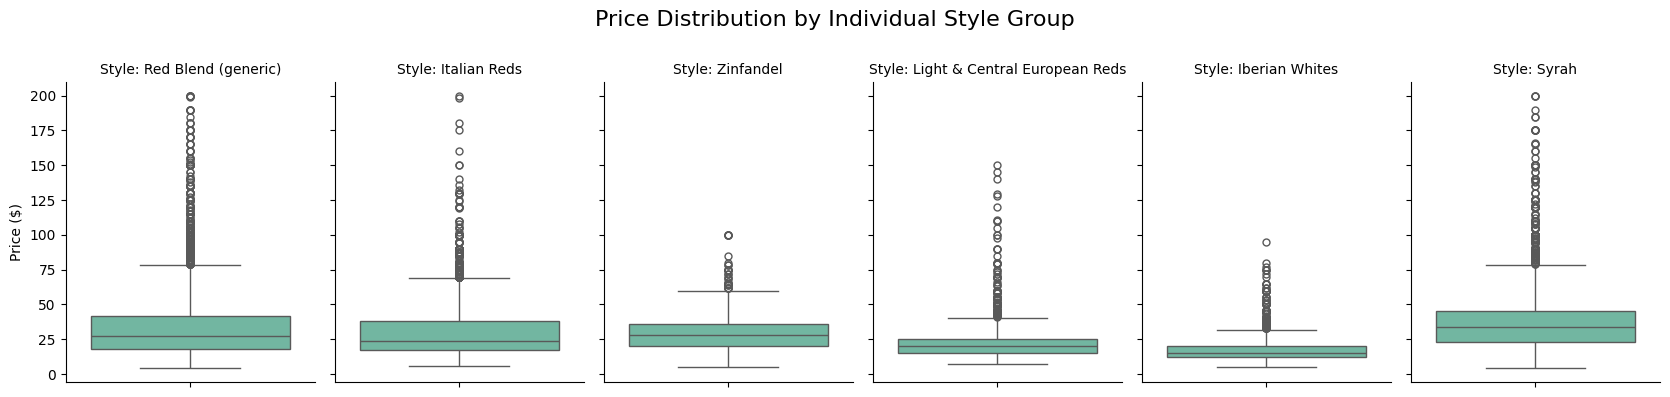

In [87]:
import matplotlib.pyplot as plt
import seaborn as sns

df_plot = wine_filtered.dropna(subset=['price', 'style_group']).copy()
df_plot = df_plot[df_plot['price'] <= 200]

g = sns.catplot(
    data=df_plot,
    y='price',
    col='style_group',
    kind='box',
    height=4,
    aspect=0.7,
    palette='Set2' # Keeps the price scale identical across all boxes for fair comparison
)

# 3. Add titles and clean up labels
g.set_axis_labels("", "Price ($)")
g.set_titles(col_template="Style: {col_name}")
g.fig.subplots_adjust(top=0.8)
g.fig.suptitle('Price Distribution by Individual Style Group', fontsize=16)

plt.show()

In [88]:
df_plotB = wine_filtered.dropna(subset=['price', 'style_group']).copy()

In [89]:
df_plotB.groupby('style_group')['price'].describe()

,count,mean,std,min,25%,50%,75%,max
style_group,,,,,,,,
Iberian Whites,2430.0,17.348148,9.176228,5.0,12.0,15.0,20.0,95.0
Italian Reds,3014.0,31.435965,27.295832,6.0,17.0,24.0,38.0,530.0
Light & Central European Reds,1523.0,23.879186,15.544810,7.0,15.0,20.0,25.0,224.0
Red Blend (generic),9179.0,35.427280,31.048027,4.0,18.0,27.0,43.0,600.0
Syrah,4908.0,39.540546,36.716943,4.0,23.0,34.0,46.0,850.0
Zinfandel,2911.0,29.177946,12.312928,5.0,20.0,28.0,36.0,100.0


What does the point distribution look like for each style group?

/tmp/ipykernel_1481/3581808293.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  g = sns.catplot(


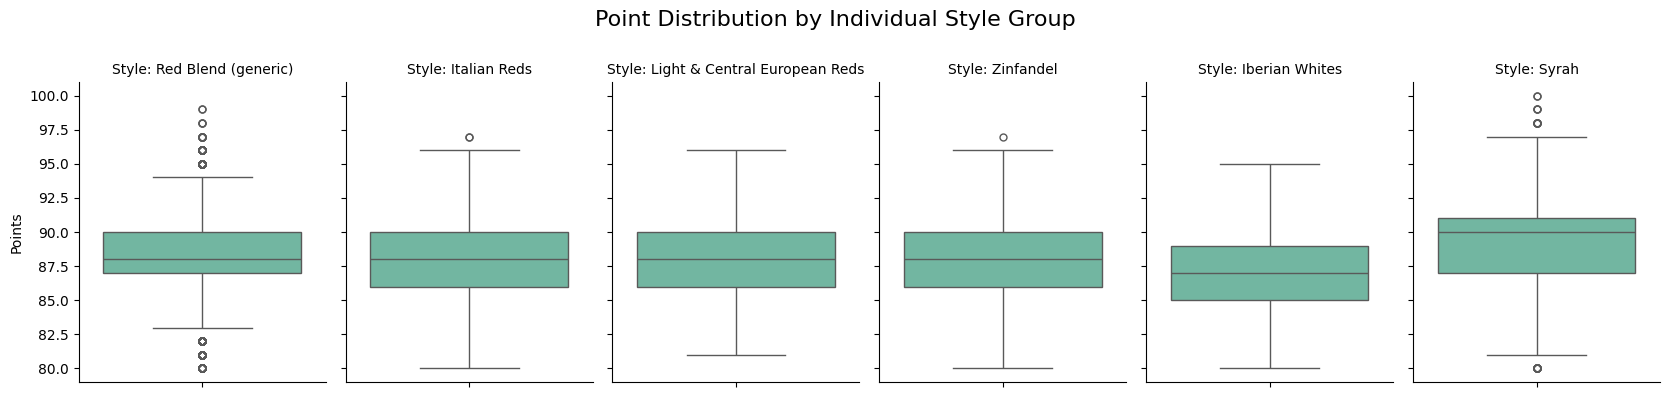

In [90]:
df_plot2 = wine_filtered.dropna(subset=['points', 'style_group']).copy()

g = sns.catplot(
    data=df_plot2,
    y='points',
    col='style_group',
    kind='box',
    height=4,
    aspect=0.7,
    palette='Set2' # Keeps the price scale identical across all boxes for fair comparison
)

# 3. Add titles and clean up labels
g.set_axis_labels("", "Points")
g.set_titles(col_template="Style: {col_name}")
g.fig.subplots_adjust(top=0.8)
g.fig.suptitle('Point Distribution by Individual Style Group', fontsize=16)

plt.show()

In [91]:
df_plot2B = wine_filtered.dropna(subset=['points', 'style_group']).copy()

df_plot2B.groupby('style_group')['points'].describe()

,count,mean,std,min,25%,50%,75%,max
style_group,,,,,,,,
Iberian Whites,2669.0,87.011615,2.486594,80.0,85.0,87.0,89.0,95.0
Italian Reds,3438.0,87.922920,2.504612,80.0,86.0,88.0,90.0,97.0
Light & Central European Reds,1787.0,88.387241,2.598133,81.0,86.0,88.0,90.0,96.0
Red Blend (generic),9683.0,88.371476,2.805931,80.0,87.0,88.0,90.0,99.0
Syrah,4978.0,89.248292,3.051270,80.0,87.0,90.0,91.0,100.0
Zinfandel,2936.0,87.764986,3.075531,80.0,86.0,88.0,90.0,97.0


What does the relationship between point and price for each style group?

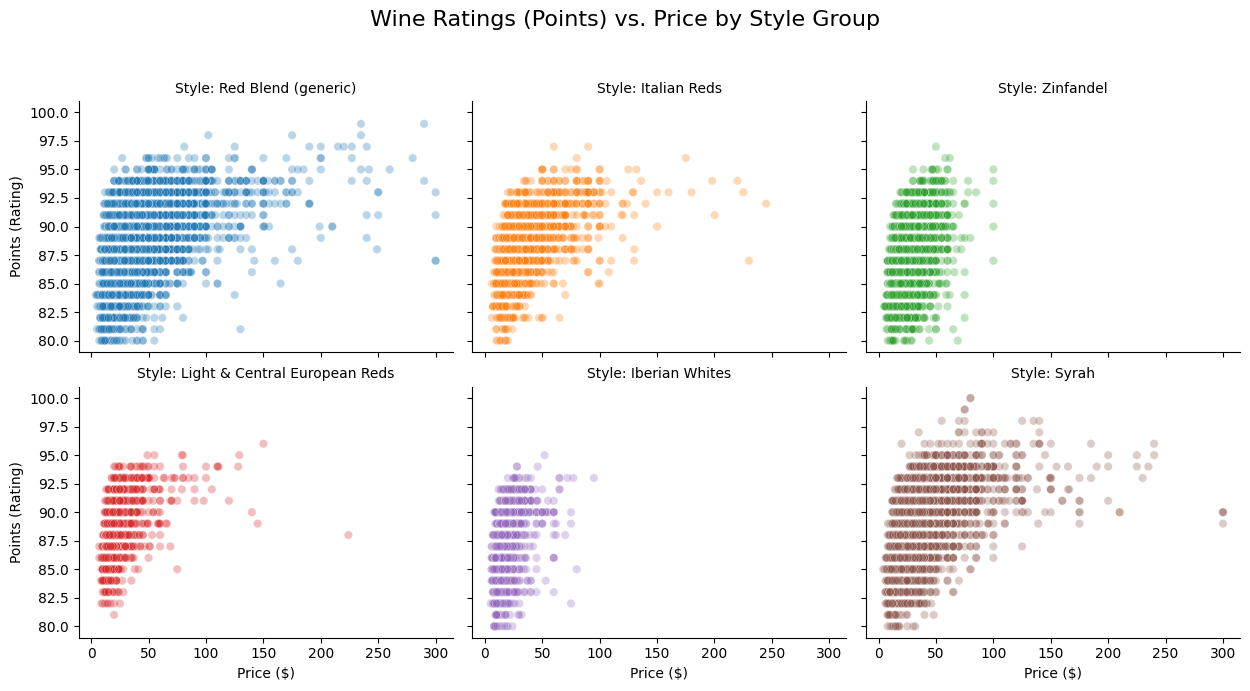

In [95]:
df_plot3 = wine_filtered.dropna(subset=['price', 'points', 'style_group']).copy()

# Optional: Cap price at $300 to keep the chart clean and avoid extreme outliers skewing the view
df_plot3 = df_plot3[df_plot3['price'] <= 300]

# 2. Create faceted scatter plots (one panel per style group)
g = sns.relplot(
    data=df_plot3,
    x='price',
    y='points',
    col='style_group',
    col_wrap=3,          # Wraps the panels into a grid of 3 columns
    kind='scatter',
    alpha=0.3,           # Transparency so overlapping points show density
    height=3.5,
    aspect=1.2,
    hue='style_group',
    palette='tab10',
    legend=False
)

# 3. Add titles and clean labels
g.set_axis_labels("Price ($)", "Points (Rating)")
g.set_titles(col_template="Style: {col_name}")
g.fig.subplots_adjust(top=0.85)
g.fig.suptitle('Wine Ratings (Points) vs. Price by Style Group', fontsize=16)

plt.show()

What are the most common countries for these wine style groups altogether?

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14],
 [Text(0, 0, 'US'),
  Text(1, 0, 'Italy'),
  Text(2, 0, 'Spain'),
  Text(3, 0, 'France'),
  Text(4, 0, 'Portugal'),
  Text(5, 0, 'Australia'),
  Text(6, 0, 'Chile'),
  Text(7, 0, 'Austria'),
  Text(8, 0, 'Argentina'),
  Text(9, 0, 'South Africa'),
  Text(10, 0, 'Israel'),
  Text(11, 0, 'Greece'),
  Text(12, 0, 'New Zealand'),
  Text(13, 0, 'Germany'),
  Text(14, 0, 'Uruguay')])

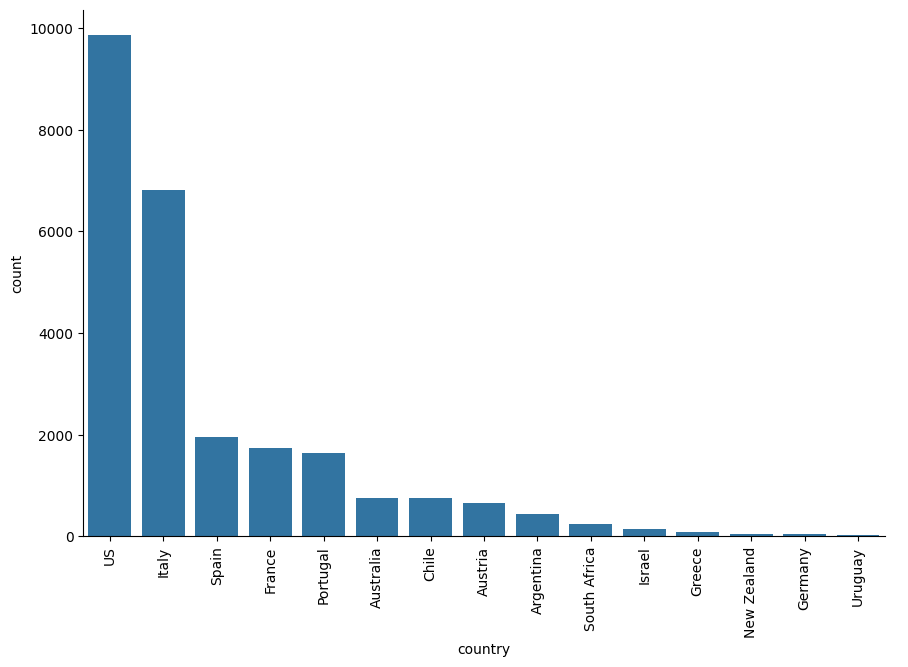

In [93]:
# looking at counts of countries
country = wine_filtered.groupby('country').size().reset_index(name='count')
country = country.sort_values(by='count', ascending=False).head(15)
sns.catplot(data=country, x='country', y='count', kind='bar', height=6, aspect=1.5)
plt.xticks(rotation=90)

What are the most common countries for each style type?



/tmp/ipykernel_1481/4151037247.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  g = sns.catplot(


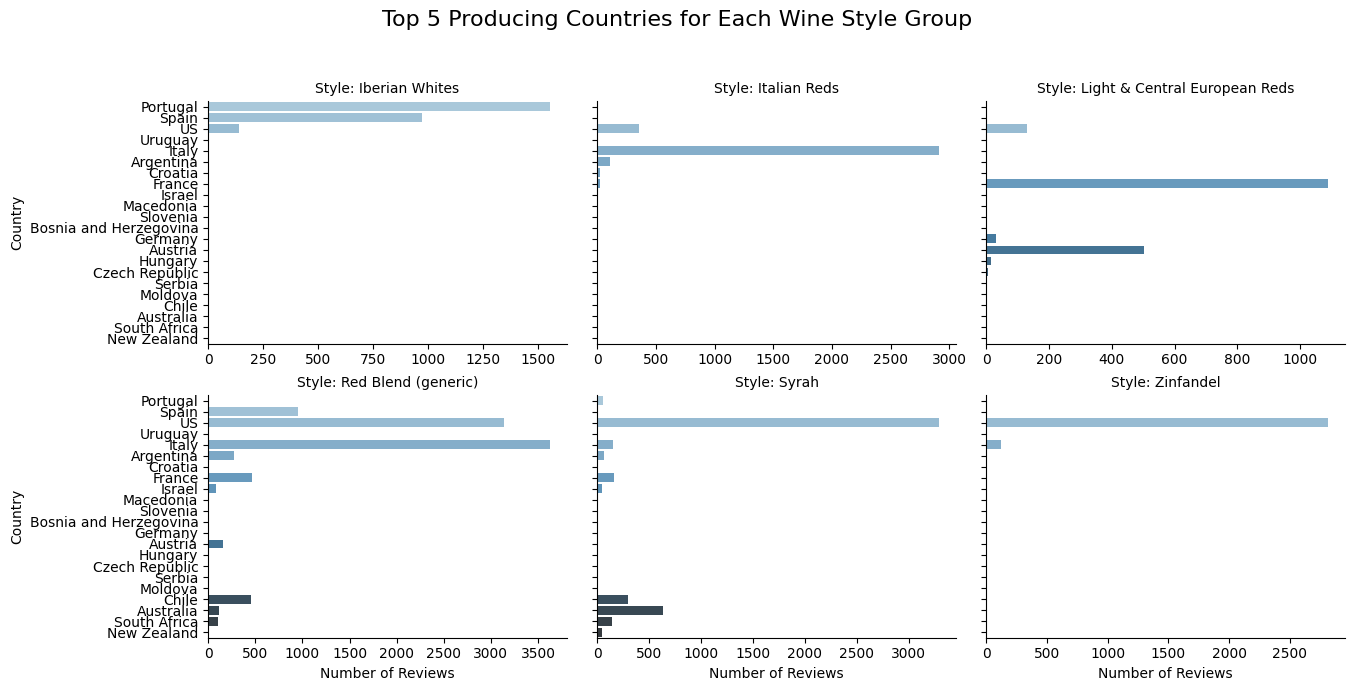

In [57]:
style_country = wine_filtered.dropna(subset=['country', 'style_group']).copy()

top_countries = (
    style_country.groupby(['style_group', 'country'])
    .size()
    .reset_index(name='count')
    .sort_values(['style_group', 'count'], ascending=[True, False])
    .groupby('style_group')
    .head(10) # Keeps the top 5 countries for each style group
)

# 3. Create faceted horizontal bar plots (one panel per style group)
g = sns.catplot(
    data=top_countries,
    x='count',
    y='country',
    col='style_group',
    col_wrap=3,          # Wraps the panels into a clean grid (up to 3 per row)
    kind='bar',
    height=3.5,
    aspect=1.3,
    sharex=False,        # Allows each style group to have its own independent x-axis scale
    palette='Blues_d'
)

# 4. Clean up labels and titles
g.set_axis_labels("Number of Reviews", "Country")
g.set_titles(col_template="Style: {col_name}")
g.fig.subplots_adjust(top=0.85)
g.fig.suptitle('Top 5 Producing Countries for Each Wine Style Group', fontsize=16)

plt.show()

In [44]:
country_style_pivot = pd.crosstab(
    wine_filtered['country'],
    wine_filtered['style_group'],
    margins=True
).sort_values(by='All', ascending=False)

print(country_style_pivot.head(15))

style_group   Iberian Whites  Italian Reds  Light & Central European Reds  \
country                                                                     
All                     2669          3437                           1784   
US                       138           359                            130   
Italy                      1          2911                              1   
Spain                    972             0                              0   
France                     0            20                           1089   
Portugal                1552             0                              0   
Australia                  0             1                              0   
Chile                      0             0                              1   
Austria                    0             1                            503   
Argentina                  0           106                              1   
South Africa               0             0                              0   